# Where should a defender put intrusion-detection sensors?
### Weighted minimum vertex cover with QAOA on IBM quantum hardware — USC × IBM Qiskit Fall Fest 2026 (Quantum Optimization)

A network defender wants **every link watched by at least one IDS sensor**. A sensor on a device watches all of that device's links, and sensors cost different amounts on different devices. Picking the cheapest set of devices is the **weighted minimum vertex cover** problem, which is NP-hard in general.

This notebook:
1. builds a small enterprise network and writes sensor placement as a QUBO,
2. solves it exactly by brute force (the ground truth every quantum result is checked against),
3. shows that **standard QAOA fails** here, and fixes it with a **CVaR objective**,
4. runs the circuit on a simulated noisy IBM Heron chip with readout-error mitigation,
5. studies how results scale with network size, and
6. reports real IBM hardware runs (raw vs. dynamical decoupling + twirling vs. readout mitigation).

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import qiskit, qiskit_ibm_runtime
import sensor_qaoa as sq
import run_on_hardware as rh
print("qiskit", qiskit.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

qiskit 2.6.2 | qiskit-ibm-runtime 0.52.1


## 1. The network
Devices are nodes, links are edges, and each node is labeled with its relative sensor cost. The firewall is cheapest (it already has monitoring hooks); servers need host agents; the admin workstation is the most expensive to instrument.

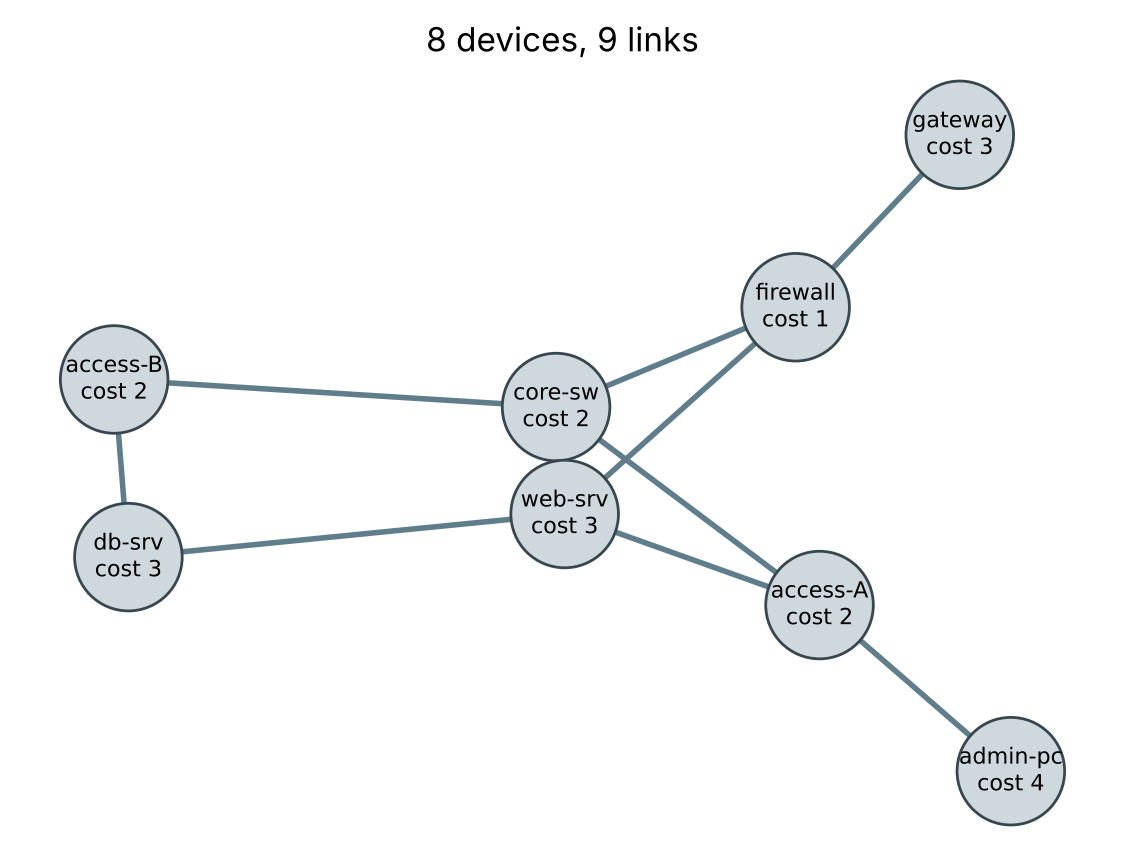

In [2]:
net = sq.enterprise_network()
G = net.graph()
pos = nx.kamada_kawai_layout(G)

def draw(net, chosen=(), title="", ax=None):
    ax = ax or plt.gca()
    g = net.graph()
    colors = ["#d1495b" if i in chosen else "#cfd8dc" for i in g.nodes]
    nx.draw_networkx_edges(g, pos, ax=ax, width=2, edge_color="#607d8b")
    nx.draw_networkx_nodes(g, pos, ax=ax, node_color=colors, node_size=1500, edgecolors="#37474f")
    nx.draw_networkx_labels(g, pos, ax=ax, font_size=8,
                            labels={i: f"{net.names[i]}\ncost {net.weights[i]:g}" for i in g.nodes})
    ax.set_title(title); ax.axis("off")

plt.figure(figsize=(7, 5)); draw(net, title=f"{net.n} devices, {len(net.edges)} links"); plt.show()

## 2. Sensor placement as a QUBO
Let $x_i = 1$ mean "sensor on device $i$" and $w_i$ its cost. Every uncovered link $(u,v)$ pays a penalty $P$:

$$C(x) = \sum_i w_i x_i \; + \; P \sum_{(u,v)} (1-x_u)(1-x_v)$$

We use $P = \sum_i w_i + 1$, so leaving any link uncovered always costs more than covering it. Substituting $x_i = (1 - Z_i)/2$ gives a diagonal Ising Hamiltonian $H$ with one qubit per device. The check below confirms that $H$ reproduces $C(x)$ for **all** $2^n$ placements.

In [3]:
P = sq.default_penalty(net)
H, scale, offset = sq.ising_hamiltonian(net, P)
print(f"penalty P = {P:g},  Hamiltonian terms = {len(H)},  qubits = {H.num_qubits}")
print(f"max |H-energy - QUBO cost| over all {2**net.n} placements: {sq.verify_hamiltonian(net, P):.1e}")

penalty P = 21,  Hamiltonian terms = 17,  qubits = 8
max |H-energy - QUBO cost| over all 256 placements: 2.8e-14


## 3. Classical ground truth (brute force)

optimal sensor cost = 8   (3 optimal placements of 256)
   ['firewall', 'access-A', 'access-B', 'web-srv']
   ['firewall', 'core-sw', 'access-A', 'db-srv']
   ['firewall', 'access-A', 'access-B', 'db-srv']


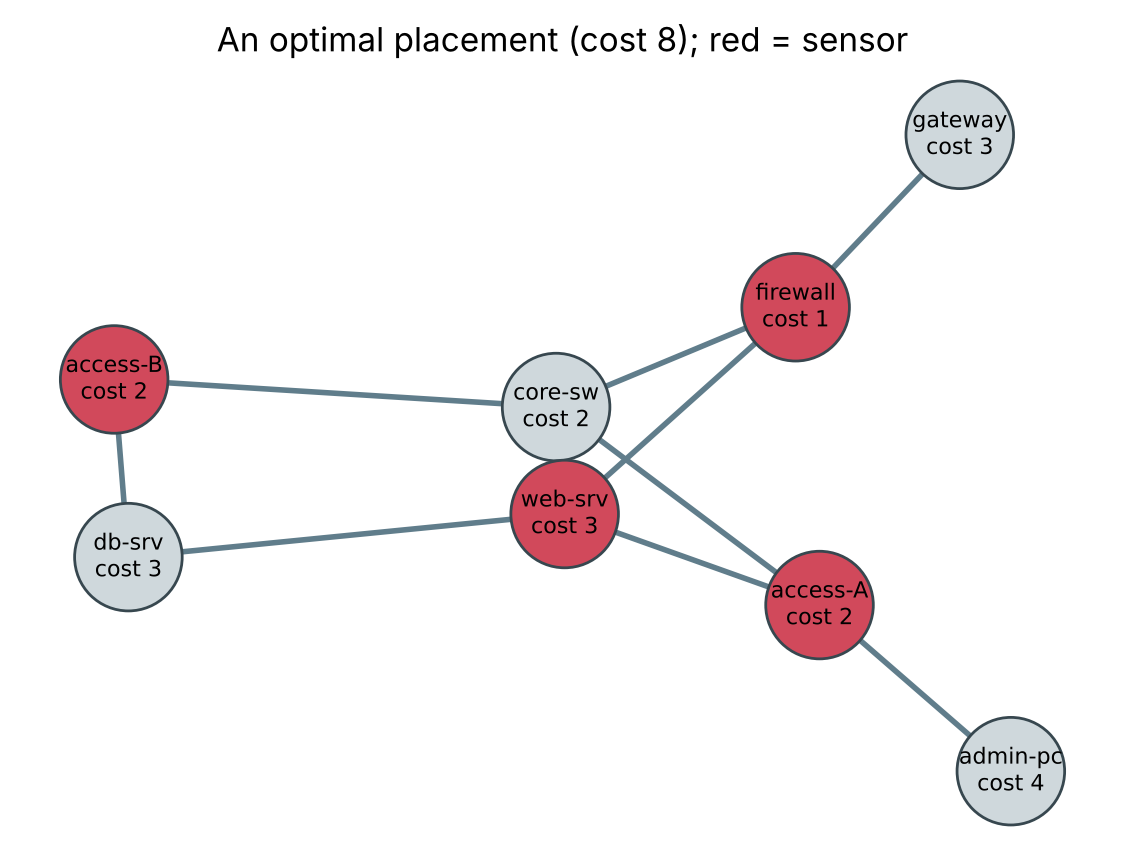

In [4]:
exact = sq.brute_force(net, P)
print(f"optimal sensor cost = {exact.optimum:g}   ({len(exact.optimal_indices)} optimal placements of {2**net.n})")
for k in exact.optimal_indices:
    print("  ", sq.placement(net, k))
best = exact.optimal_indices[0]
plt.figure(figsize=(7, 5))
draw(net, chosen=[i for i in range(net.n) if sq.index_to_bits(best, net.n)[i]],
     title=f"An optimal placement (cost {exact.optimum:g}); red = sensor")
plt.show()

## 4. QAOA: the standard objective fails, CVaR fixes it
QAOA angles are optimized on an ideal simulator (no hardware time). We compare two objectives:
* **Standard:** minimize the average cost $\langle H \rangle$ of all measured outcomes.
* **CVaR ($\alpha = 0.2$):** minimize the average cost of only the best 20% of outcomes (Barkoutsos et al., *Quantum* 2020). For optimization we only care about the best answer we see, not the average.

In [5]:
t0 = time.time()
naive = sq.optimize_qaoa(net, reps=2, alpha=1.0)
cvar = sq.optimize_qaoa(net, reps=2, alpha=0.2)
print(f"optimized both in {time.time() - t0:.1f} s on the simulator")
rows = {"standard (average)": sq.summarize(naive.probs, exact), "CVaR alpha=0.2": sq.summarize(cvar.probs, exact)}
print(f"\n{'objective':<20} {'P(optimal)':>10} {'x random':>9} {'P(valid)':>9}   most likely answer")
for name, s in rows.items():
    top = "an optimal placement" if s.most_likely_is_optimal else f"cost {s.most_likely_cost:g} (not optimal)"
    print(f"{name:<20} {s.p_optimal:10.3f} {s.advantage_over_random:9.1f} {s.p_valid:9.3f}   {top}")
print(f"\nrandom guessing finds an optimum with probability {rows['CVaR alpha=0.2'].random_guess_p_optimal:.4f}")
ml = int(np.argmax(naive.probs))
print("standard QAOA's most likely answer puts sensors on:", sq.placement(net, ml))

# save the angles so run_on_hardware.py uses exactly these
Path("qaoa_params.json").write_text(json.dumps({"reps": 2, "cvar_alpha": 0.2,
    "cvar_params": cvar.params.tolist(), "naive_params": naive.params.tolist()}, indent=2))

optimized both in 10.4 s on the simulator

objective            P(optimal)  x random  P(valid)   most likely answer
standard (average)        0.033       2.8     0.972   cost 20 (not optimal)
CVaR alpha=0.2            0.203      17.3     0.517   an optimal placement

random guessing finds an optimum with probability 0.0117
standard QAOA's most likely answer puts sensors on: ['gateway', 'firewall', 'core-sw', 'access-A', 'access-B', 'web-srv', 'db-srv', 'admin-pc']


274

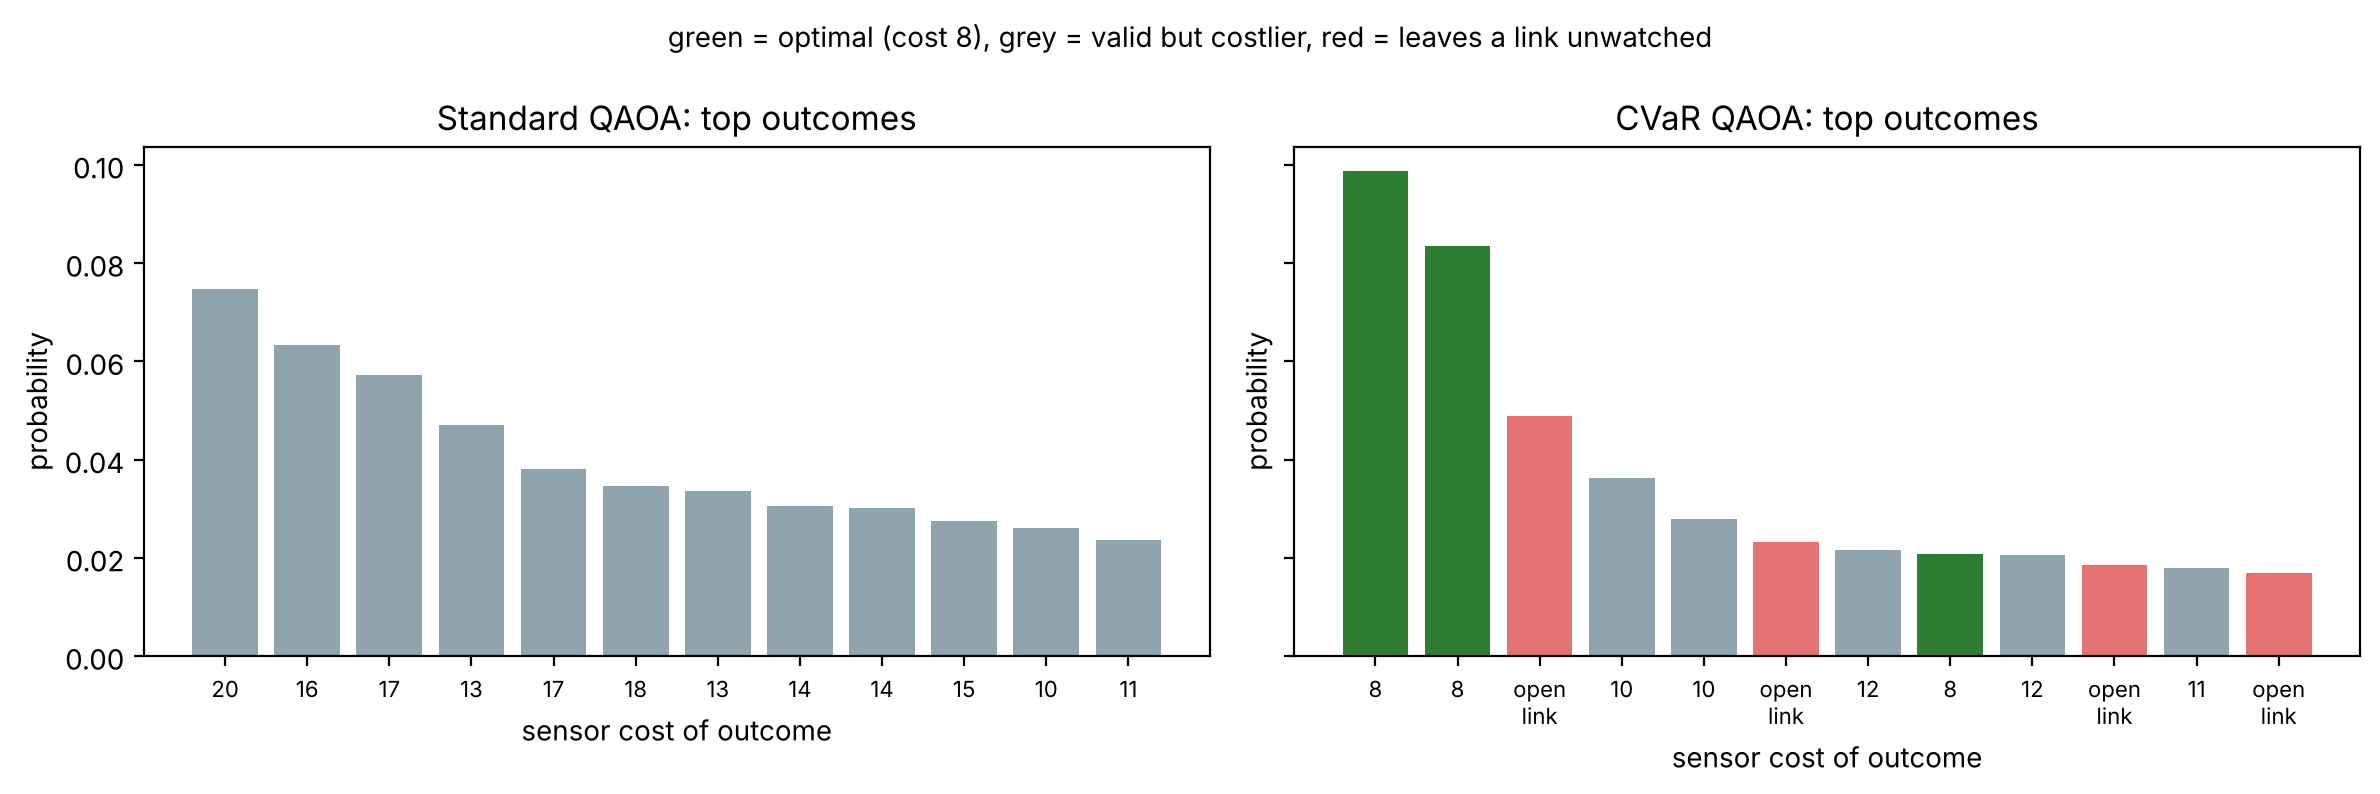

In [6]:
def outcome_bars(probs, title, ax, top=12):
    idx = np.argsort(probs)[::-1][:top]
    colors = ["#2e7d32" if exact.optimal_mask[k] else ("#90a4ae" if np.isfinite(exact.sensor_costs[k]) else "#e57373") for k in idx]
    labels = [f"{exact.sensor_costs[k]:g}" if np.isfinite(exact.sensor_costs[k]) else "open\nlink" for k in idx]
    ax.bar(range(len(idx)), probs[idx], color=colors)
    ax.set_xticks(range(len(idx)), labels, fontsize=8); ax.set_xlabel("sensor cost of outcome")
    ax.set_ylabel("probability"); ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
outcome_bars(naive.probs, "Standard QAOA: top outcomes", axes[0])
outcome_bars(cvar.probs, "CVaR QAOA: top outcomes", axes[1])
fig.suptitle("green = optimal (cost %g), grey = valid but costlier, red = leaves a link unwatched" % exact.optimum, fontsize=10)
plt.tight_layout(); plt.show()

**Why the standard objective fails:** with a large penalty, the safest way to get a low *average* is to put sensors almost everywhere, since that never leaves a link open. QAOA learns exactly that, so its most likely answer is an expensive placement. CVaR only scores the best tail of outcomes, so the optimizer is rewarded for making the optimal placements likely, even though it then produces more invalid outcomes (lower P(valid)). Invalid outcomes are harmless here because each sample is checked classically and the cheapest valid one is kept.

## 5. Simulated noisy IBM Heron + readout-error mitigation
The same circuit is compiled for a 156-qubit IBM Heron device model (`FakeFez`, a noisy simulator built from real calibration data) and run through the same Runtime `SamplerV2` code used on real hardware. Two extra circuits (all-0 and all-1) measure each qubit's readout error, which we then undo in post-processing (tensored readout mitigation).

In [7]:
from qiskit_ibm_runtime.fake_provider import FakeFez
backend = FakeFez()
params = json.loads(Path("qaoa_params.json").read_text())
pubs, info = rh.build_pubs(net, params, backend, shots=4000)
print(f"compiled for {backend.name}: depth {info['depth']}, {info['two_qubit_gates']} two-qubit gates, physical qubits {info['layout']}")
result = rh.make_sampler(backend, mitigated=False).run(pubs).result()
sim_counts = {"raw": {name: rh.counts_of(result[i]) for i, name in enumerate(rh.PUB_NAMES)}}
sim_table = rh.analyze(net, sim_counts)
rh.print_table(sim_table)

compiled for fake_fez: depth 134, 57 two-qubit gates, physical qubits [123, 136, 143, 142, 146, 144, 145, 141]



variant                                   P(opt)  x random  P(valid)  top answer
qaoa_cvar | raw                            0.166      14.1     0.462     optimal
qaoa_cvar | raw+readout                    0.172      14.7     0.466     optimal
qaoa_naive | raw                           0.032       2.8     0.887     cost 16
qaoa_naive | raw+readout                   0.033       2.8     0.900     cost 16
mean readout error | raw: 0.0067


## 6. Scaling: how does this hold up as networks grow?
Random connected networks (a random spanning tree plus redundant links, random sensor costs 1–4), 3 networks per size. For each we compare standard vs. CVaR QAOA on the ideal simulator, and record the circuit size after compiling for the Heron device model.

In [8]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
pm = generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=7)
sizes, seeds = [6, 8, 10, 12, 14], [1, 2, 3]
scaling = []
t0 = time.time()
for n in sizes:
    for seed in seeds:
        rnet = sq.random_network(n, seed)
        rex = sq.brute_force(rnet, sq.default_penalty(rnet))
        row = {"n": n, "seed": seed, "links": len(rnet.edges)}
        for label, alpha in (("standard", 1.0), ("cvar", 0.2)):
            r = sq.optimize_qaoa(rnet, reps=2, alpha=alpha, starts=4, maxiter=300, seed=seed)
            s = sq.summarize(r.probs, rex)
            row[f"{label}_p_opt"] = s.p_optimal
            row[f"{label}_x_random"] = s.advantage_over_random
            row[f"{label}_top_is_opt"] = s.most_likely_is_optimal
        isa = pm.run(sq.measured(r.circuit))
        row["two_qubit_gates"] = sum(v for k, v in isa.count_ops().items() if k in ("cz", "ecr", "cx"))
        row["depth"] = isa.depth()
        scaling.append(row)
print(f"scaling study done in {time.time() - t0:.0f} s")
print(f"\n{'n':>3} {'seed':>4} {'links':>5} | {'P(opt) std':>10} {'P(opt) CVaR':>11} | {'CVaR x random':>13} | {'top=opt std/CVaR':>16} | {'2q gates':>8}")
for r in scaling:
    print(f"{r['n']:>3} {r['seed']:>4} {r['links']:>5} | {r['standard_p_opt']:10.3f} {r['cvar_p_opt']:11.3f} | {r['cvar_x_random']:13.1f} | "
          f"{str(r['standard_top_is_opt']):>7}/{str(r['cvar_top_is_opt']):<8} | {r['two_qubit_gates']:>8}")
Path("scaling_results.json").write_text(json.dumps(scaling, indent=2))

scaling study done in 177 s

  n seed links | P(opt) std P(opt) CVaR | CVaR x random | top=opt std/CVaR | 2q gates
  6    1     7 |      0.184       0.249 |           4.0 |   False/True     |       43
  6    2     7 |      0.056       0.074 |           4.7 |   False/False    |       40
  6    3     7 |      0.037       0.190 |          12.1 |   False/True     |       44
  8    1    10 |      0.010       0.077 |          19.7 |   False/True     |       73
  8    2    10 |      0.000       0.100 |          12.8 |   False/True     |       79
  8    3    10 |      0.020       0.064 |           8.2 |   False/False    |       67
 10    1    13 |      0.003       0.018 |          18.0 |   False/False    |       98
 10    2    13 |      0.000       0.021 |          21.7 |   False/True     |      100
 10    3    13 |      0.003       0.030 |          31.1 |   False/False    |      100
 12    1    15 |      0.001       0.011 |          23.4 |   False/False    |      120
 12    2    15 |      0.0

4961

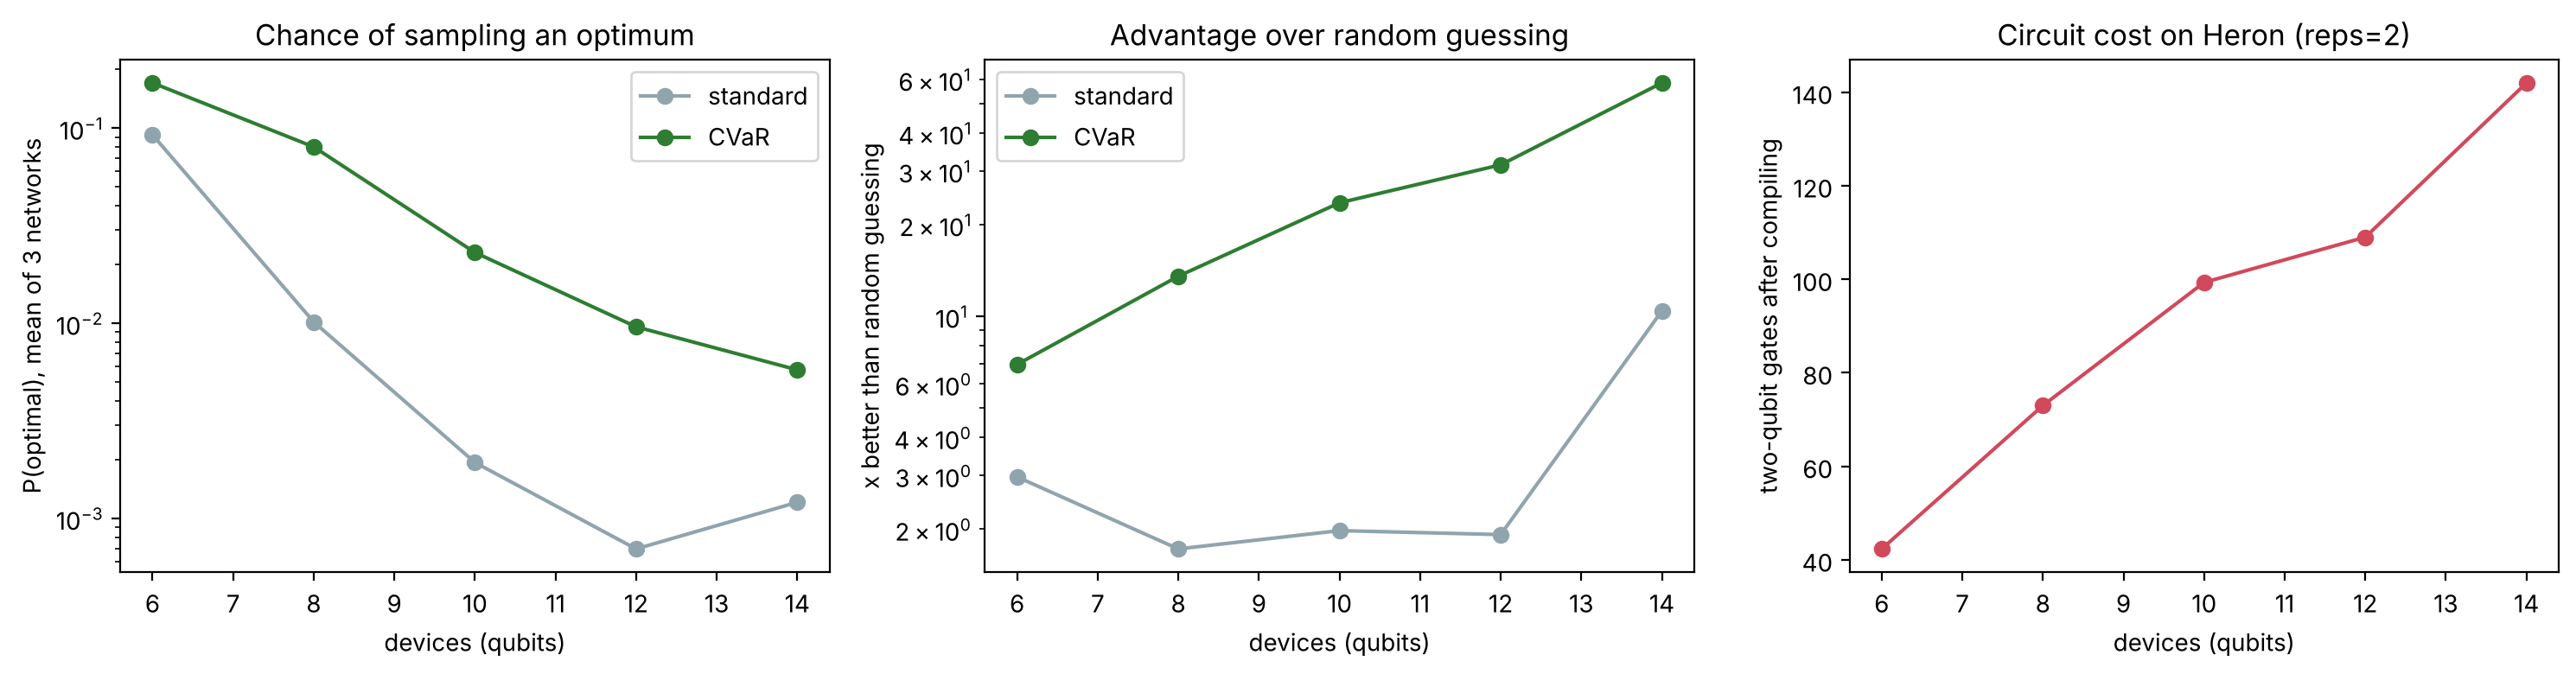

In [9]:
def mean_by_n(key):
    return [np.mean([r[key] for r in scaling if r["n"] == n]) for n in sizes]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(sizes, mean_by_n("standard_p_opt"), "o-", label="standard", color="#90a4ae")
axes[0].plot(sizes, mean_by_n("cvar_p_opt"), "o-", label="CVaR", color="#2e7d32")
axes[0].set(xlabel="devices (qubits)", ylabel="P(optimal), mean of 3 networks", title="Chance of sampling an optimum", yscale="log"); axes[0].legend()
axes[1].plot(sizes, mean_by_n("standard_x_random"), "o-", label="standard", color="#90a4ae")
axes[1].plot(sizes, mean_by_n("cvar_x_random"), "o-", label="CVaR", color="#2e7d32")
axes[1].set(xlabel="devices (qubits)", ylabel="x better than random guessing", title="Advantage over random guessing", yscale="log"); axes[1].legend()
axes[2].plot(sizes, mean_by_n("two_qubit_gates"), "o-", color="#d1495b")
axes[2].set(xlabel="devices (qubits)", ylabel="two-qubit gates after compiling", title="Circuit cost on Heron (reps=2)")
plt.tight_layout(); plt.show()

## 7. Real quantum hardware
The same circuits, with the same optimized angles, ran on two real quantum computers on Nov 14, 2026. Each run includes the CVaR circuit, the standard-objective circuit (4,000 shots each), and all-0 / all-1 readout-calibration circuits on the same physical qubits, so readout mitigation can be applied afterwards. No optimization runs on hardware.

### 7a. IBM `ibm_fez` (Heron), via `run_on_hardware.py`
`ibm_fez` is the chip that `FakeFez` in Section 5 models. Two jobs: **raw**, and **mitigated** (dynamical decoupling + Pauli twirling of gates and measurements). Compiled circuit: 57 two-qubit gates, depth 135. Total QPU time: 13 seconds.

* **With error suppression, the simulator story reappears on hardware.** CVaR's two most common answers were both optimal placements (89 and 81 of 4,000 shots; the next answer had 70). Its raw P(opt) was 0.053 (95% CI 0.047–0.061; 0.057 with readout mitigation), 4.5× random (z = 24). Standard QAOA's most common answer was sensors on all 8 devices, with P(opt) 0.015 (1.3×).
* **CVaR beat standard QAOA in both jobs** (P(opt) higher by z = 8.7 raw, z = 9.3 with suppression).
* **Error suppression mattered:** it raised CVaR's P(opt) from 0.035 to 0.053 (z = 4.0) and moved its top answer from invalid to optimal. Without it, CVaR's P(valid) (0.184) matched random guessing.
* **Still a weak signal:** the margins at the top are small, and `FakeFez` predicted about three times the real P(opt) (≈ 0.16 vs 0.053). Mean readout error was 1.6–1.8%.


In [10]:
hw = Path("hardware_results.json")
if not hw.exists():
    print("No IBM hardware results yet. Run:  python run_on_hardware.py --submit   then   python run_on_hardware.py --fetch")
else:
    data = json.loads(hw.read_text())
    print(f"machine: {data['backend']}   submitted (UTC): {data['submitted_utc']}   QPU seconds: {data.get('qpu_seconds')}")
    print(f"circuit on hardware: depth {data['circuit']['depth']}, {data['circuit']['two_qubit_gates']} two-qubit gates, "
          f"qubits {data['circuit']['layout']}")
    rh.print_table(data["summary"])

machine: ibm_fez   submitted (UTC): 2026-11-14T22:12:13.121919+00:00   QPU seconds: {'raw': 6, 'mitigated': 7}
circuit on hardware: depth 135, 57 two-qubit gates, qubits [125, 124, 123, 122, 144, 136, 143, 121]

variant                                   P(opt)  x random  P(valid)  top answer
qaoa_cvar | raw                            0.035       3.0     0.184     invalid
qaoa_cvar | raw+readout                    0.041       3.5     0.203     invalid
qaoa_naive | raw                           0.007       0.6     0.496     cost 19
qaoa_naive | raw+readout                   0.008       0.6     0.532     cost 19
qaoa_cvar | mitigated                      0.053       4.5     0.253     optimal
qaoa_cvar | mitigated+readout              0.057       4.9     0.255     optimal
qaoa_naive | mitigated                     0.015       1.3     0.563     cost 20
qaoa_naive | mitigated+readout             0.016       1.3     0.574     cost 20
mean readout error | raw: 0.0163
mean readout error | mitig

### 7b. Rigetti Cepheus-1-108Q via Amazon Braket (`run_on_braket.py`)
Run first, while IBM signup was failing, through Amazon Braket with `qiskit-braket-provider`: Qiskit compiles to the device's native gates and layout and submits *verbatim*. Braket has no IBM-style dynamical decoupling or twirling, so this is a raw run plus readout mitigation.

**Result (45 two-qubit gates, depth 135): without error suppression, noise won, and it hit CVaR hardest.**
* All 256 placements appeared for both circuits, and neither top answer was a valid placement.
* **CVaR's output was essentially random:** P(valid) 0.187 vs 0.184 for random guessing (z = 0.6); P(opt) 0.018 (95% CI 0.015–0.023) → 0.020 with readout mitigation (1.7× random); outcome spread 7.7 of a possible 8 bits.
* **Standard QAOA kept some structure:** P(valid) 0.27, P(opt) 0.043 (95% CI 0.037–0.050) → 0.051 with readout mitigation (4.4× random), well above random (z > 13) and above CVaR (z = 6.4). A likely reason, not tested here: its broad lean toward "more sensors" survives noise, while CVaR's sharp peak on the exact optima needs fine interference that noisy gates destroy.
* **Readout was not the cause:** the calibration circuits read back correctly (per-qubit readout error 0–8%, mean 3.4%). The errors built up over the circuit's gates.
* **The noise models were optimistic:** Braket's own emulator of this device predicted P(opt) 0.11 with an optimal top answer (`braket_results_emulator_cepheus.json`).


In [10]:
hw = Path("braket_results.json")
if not hw.exists():
    print("No hardware results yet. Run:  python run_on_braket.py --submit --device cepheus --yes   then   python run_on_braket.py --fetch")
else:
    data = json.loads(hw.read_text())
    print(f"device: {data['backend']}   submitted (UTC): {data['submitted_utc']}")
    print(f"circuit on hardware: depth {data['circuit']['depth']}, {data['circuit']['two_qubit_gates']} two-qubit gates, "
          f"measured qubits {data['circuit']['measured_qubits']}")
    rh.print_table(data["summary"])

device: Cepheus-1-108Q   submitted (UTC): 2026-11-14T16:49:30.619750+00:00
circuit on hardware: depth 135, 45 two-qubit gates, measured qubits [31, 22, 12, 21, 4, 13, 5, 11]

variant                                   P(opt)  x random  P(valid)  top answer
qaoa_cvar | cepheus                        0.018       1.6     0.187     invalid
qaoa_cvar | cepheus+readout                0.020       1.7     0.214     invalid
qaoa_naive | cepheus                       0.043       3.7     0.266     invalid
qaoa_naive | cepheus+readout               0.051       4.4     0.311     invalid
mean readout error | cepheus: 0.0336


## 8. Honest conclusions and limitations
* **No quantum advantage here, and none is claimed.** Brute force solves these networks instantly; this project measures how well today's QAOA and today's hardware do on a security-relevant problem.
* **Standard QAOA is a trap for penalty-based problems:** it converges to "sensors everywhere." Switching the objective to CVaR makes the optimal placements the most likely outputs, at the cost of more invalid samples, which are discarded classically.
* **Real hardware:** on IBM `ibm_fez` with dynamical decoupling and twirling, CVaR's two most common answers were optimal and it beat standard QAOA (4.5× vs 1.3× random), so the main finding holds on real hardware, though much more weakly than on the simulator. On Rigetti Cepheus, with no comparable error suppression, CVaR's output was indistinguishable from random. These are single runs on different chips, so they suggest, rather than prove, that error suppression is what lets CVaR's advantage survive today's noise.
* **Scaling:** see Section 6 for how P(optimal) and the advantage over random guessing change with network size, and how quickly circuit size grows at a fixed QAOA depth.
* **Mitigation assumptions:** readout mitigation assumes independent (tensored) readout errors; dynamical decoupling and twirling only run on real hardware (local simulators ignore them).
* **Model limits:** one sensor watches all of a device's links; real deployments also weigh traffic volume, encrypted links, and sensor capacity.